# Lab 11: Bathymetry with ICESat-2 in Python and QGIS

In this lab, we will explore how to use lidar data from NASA's ICESat-2 satellite to estimate bathymetry from space. We will see how to use both Python and QGIS side-by-side to make nice maps with corresponding plots.

This notebook has three main parts organized as follows:
1. Find and download ICESat-2 data from the NSIDC web interface
2. Plot and interpret ICESat-2 data
3. Visualize ICESat-2 ground tracks in QGIS

**Import the modules for this notebook**

To begin, let's import the modules used for this notebook

In [1]:
# import the packages used in previous notebooks
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import netCDF4 as nc4
from scipy.interpolate import griddata

# import sys, h5py, and the shapefile modules
import sys
import h5py
import shapefile

As always, also define a lab folder:

In [2]:
data_folder = '../data/labs/lab11'

## Motivation

The ocean floor in shallow coastal areas is not typically well-mapped with multibeam echo sounders to generate high resolution bathymetry maps due to the dangers posed to vessels operating in these regions. However, this bathymetric information is often important for understanding coastal ecosystems, such as coral reefs, as well as coastal hazards for ships operating in coastal environments.

One alternative for examining bathymetry in coastal areas is lidar, which can detect sea floor returns in shallow water and favorable conditions. In this lab, we will work with lidar data from the ICESat-2 satellite. We will use Python to access and plot data and we'll use QGIS for generating a nice map. At the end of this lab, you should be able to create a nice side-by-side figure of an approximated bathymetry profile using lidar data and an equivalent map showing where the lidar track is on the ground. 

### Generate a base map

To begin this lab, download some Landsat 8 or 9 data for the region around Kiribati - an island nation in the Pacific Ocean. Follow the steps from [Lab 2](https://profmikewood.github.io/ocean_remote_sensing_book/lab02-landsat-natural/) to gather the data from EarthExplorer and make a nice figure in QGIS.

Kiribati is located at approximately **1.95$^{\circ}$N, 157.45$^{\circ}$W**. With a look forward to the subsequent parts of this lab, gather data around the date **September 20, 2025**.

Your figure should resemble the following figure when completed:

```{figure} ../images/labs/lab11/Kiribati.png
---
height: 400px
name: kiribati
---
Screenshot of a "Natural Color" Landsat 9 image of Kiribati generated in QGIS.
```
As we can see in the image above, Kiribati has a large lagoon on its main island. In this lab, we will visualize the depth of this lagoon using ICESat-2.

## Part 1: Downloading Data using NSIDC

To gather ICESat-2 data for this location, we will use a query in the [National Snow and Ice Data Center ICESat-2 ATL03 Product](https://nsidc.org/data/atl03/versions/7). We will use the NSIDC data access tool to find data for our time and location of interest.

### Defining a Query on the NSIDC Webpage

Using the information given above, build a query to search for a file in the time range 9/20/25-9/21/25 and a spatial range bounded by -157.59$^{\circ}$W, 1.8$^{\circ}$S, -157.28$^{\circ}$W, and 2$^{\circ}$N.

Your query should look like the following screenshot:
```{figure} ../images/labs/lab11/icesat2_granule_selection.png
---
height: 400px
name: nsdic-query
---
Screenshot of a data request from the NSIDC portal for an ICESat-2 ATL03 granule.
```

Next, click the **Download Script** button at the bottom of the page and store the script as `nsidc.py` in your lab folder. We can access this file in our Jupyter book by ensuring our `data_folder` is on our searchable Python path:

In [3]:
# add the data directory to the import path
sys.path.append(data_folder)

# import the nsidc module
import nsidc

### Defining a Query in Python
The download script obtained above can be run as-is to download the files that match out time and region of interest, as listed on the NSIDC site. This works because the file has actually hard-coded the info we put into our query in the script:

```{code}
short_name = "ATL03"
version = "007"
time_start = "2025-09-20T07:00:00Z"
time_end = "2025-09-21T06:59:59Z"
bounding_box = "-157.59,1.8,-157.28,2"
```

However, the script also contains tools for us to run the query and download the files ourselves. Here, we'll implement this query in Python to make our script flexible for future queries:

In [4]:
# define the product short_name
short_name = 'ATL03'

# define a version
version = '007'

# define the start and end times
time_start = '2025-09-20T00:00:00Z'
time_end = '2025-09-21T23:59:59Z'

# define the spatial location
min_lon = -157.59
max_lon = -157.28
min_lat = 1.8
max_lat = 2.0
polygon = ''
polygon += str(min_lon)+','+str(min_lat)+','
polygon += str(max_lon)+','+str(min_lat)+','
polygon += str(max_lon)+','+str(max_lat)+','
polygon += str(min_lon)+','+str(max_lat)+','
polygon += str(min_lon)+','+str(min_lat)

# choose whether to print out the status of the search/download
quiet = False 

# choose whether to force the download (overwrite existing files)
force = True

# cap the number of files to download - particularly useful
# when testing files or searching an area
download_cap = 1

### Query NSIDC for a list of URLs matching the criteria

In [5]:
url_list = nsidc.cmr_search(short_name, version, time_start, time_end,
                            polygon=polygon, quiet=quiet)

Querying for data:
	https://cmr.earthdata.nasa.gov/search/granules.json?&sort_key[]=start_date&sort_key[]=producer_granule_id&page_size=2000&short_name=ATL03&version=007&version=07&version=7&temporal[]=2025-09-20T00:00:00Z,2025-09-21T23:59:59Z&polygon=-157.59,1.8,-157.28,1.8,-157.28,2.0,-157.59,2.0,-157.59,1.8&provider=NSIDC_CPRD

Found 1 matches.


#### Filter the url list to only contain `h5` files
When you query the files, you may pick up additional files, such as `xml` files. The code block below will filter out extraneous files.

In [6]:
h5_files = []
for file_name in url_list:
    if file_name[-3:]=='.h5':
        h5_files.append(file_name)
        # print(file_name.split('/')[-1])

Let's print them out to see our results:

In [7]:
print(h5_files)

['https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/ATLAS/ATL03/007/2025/09/20/ATL03_20250920125813_00912907_007_01.h5']


As you can see, this matches the file list obtained on the NSIDC web interface.

#### Subset to the number of files indicated above
If desired, you can also use the download cap to limit the number of files that are downloaded when exploring different collections of files:

In [8]:
h5_files = h5_files[:download_cap]

### Run the downloading script
The `cmr_download` method will download the files found in the NSIDC database.

In [9]:
# run the downloading script
nsidc.cmr_download(h5_files, force=force, quiet=quiet)

1/1: ATL03_20250920125813_00912907_007_01.h5
  [============================================================] 100%  13.6MB/s   


Note that these files will download into the same directory where you are running your notebook. You can move these files to your `data_folder` with the following script:

In [10]:
for url in h5_files:
    file_name = url.split('/')[-1]
    if file_name in os.listdir(os.getcwd()):
        os.rename(os.path.join(os.getcwd(),file_name),
                  os.path.join(data_folder,file_name))

## Part 2: Plotting ICESat-2 Data

Now that we've gathered our ICESat-2 data, we will next plot the data from our file. First, we'll read in a subset of the data and then we'll examine what this looks like on a plot.

### Read in the elevation data
Using the `h5py` module, we can access data from `h5` files in the same way as for netCDF files. And you can also open them in the same way using Panoply! Open the file in Panoply first and examine the structure. Then, leverage this info to read the file in the following section:

In [11]:
# choose a file to plot
file_name = 'ATL03_20250920125813_00912907_007_01.h5'

# open the file with the h5 module
ds = h5py.File(os.path.join(data_folder,file_name), "r")

# choose a beam to read data from
beam = 'gt2l'

# read in the lon, lat, and height data from the gt2l beam
if file_name[:5] == 'ATL03':
    longitude = np.array(ds[beam]['heights']['lon_ph'])
    latitude = np.array(ds[beam]['heights']['lat_ph'])
    geoid = np.array(ds[beam]['geophys_corr']['geoid'])
    elevation = np.array(ds[beam]['heights']['h_ph'])

# this code is used when reading ATL08 data
if file_name[:5] == 'ATL08':
    longitude = np.array(ds[beam]['land_segments']['longitude'])
    latitude = np.array(ds[beam]['land_segments']['latitude'])
    dem = np.array(ds[beam]['land_segments']['dem_h'])
    elevation = np.array(ds[beam]['land_segments']['h_dif_ref'])+dem

# close the file
ds.close()

As with most data, there are values flagged as nonsense in the ICESat-2 data files. Before plotting them, be sure to remove these points or mask them:

In [12]:
# mask the elevation data
elevation[elevation>10e10] = np.nan

### Subset the data
The ICESat-2 data tracks tend to span a much larger area that we are interested in. To help with the interpretation, we can subset the data to our region of interest:

In [13]:
# define bounds (min/max x/y) to limit the data to a particular region
min_lon = -157.59141
max_lon = -157.28633
min_lat = 1.80059
max_lat = 2.06302

# find the indices within the box defined by the coordinates above
lon_indices = np.logical_and(longitude>min_lon, longitude<max_lon)
lat_indices = np.logical_and(latitude>min_lat, latitude<max_lat)
indices = np.logical_and(lon_indices, lat_indices)

# use the indices to subset the data
longitude = longitude[indices]
latitude = latitude[indices]
elevation = elevation[indices]

### Plot the data
Plot the point cloud from the ICESat-2 file:

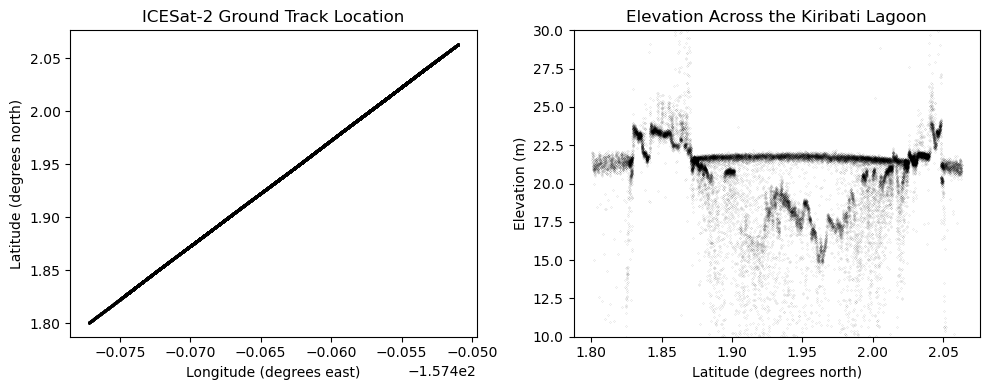

In [14]:
# make a figure
fig = plt.figure(figsize=(10,4))

# plot the longitude and latitude location in the first subplot
plt.subplot(1,2,1)
plt.plot(longitude,latitude,'k.',markersize=1)
plt.xlabel('Longitude (degrees east)')
plt.ylabel('Latitude (degrees north)')
plt.title('ICESat-2 Ground Track Location')

# plot the elevation as a function of latitude in the second subplot
plt.subplot(1,2,2)
plt.plot(latitude,elevation,'k.',markersize=0.1)
plt.title('Elevation Across the Kiribati Lagoon')
plt.gca().set_ylim([10, 30])
plt.ylabel('Elevation (m)')
plt.xlabel('Latitude (degrees north)')

plt.tight_layout()

# show the plot
plt.show()

#### &#129300; Consider these questions:
1. Where is the sea level in the elevation plot?
2. What other features do you see?
3. We might expect elevation to be 0 at sea level, but that's not the case. What is going on here?

### Removing the Geoid
In the plot above, we saw that the elevation was not 0 at sea level. Part of this explanation is that the photon heights include the geoid. Information on the geoid height is included in the file along a reference track. Let's read that in here:

In [15]:
# open the file with the h5 module
ds = h5py.File(os.path.join(data_folder,file_name), "r")
geoid_lon = np.array(ds[beam]['geolocation']['reference_photon_lon'])
geoid_lat = np.array(ds[beam]['geolocation']['reference_photon_lat'])
geoid = np.array(ds[beam]['geophys_corr']['geoid'])
ds.close()

This reference track does not include samples for each of the returned photons but instead along the reference track. Using strategies from the previous lab, we can interpolate the geoid values to the returned photon values:

In [16]:
geoid_points = griddata(np.column_stack([geoid_lon, geoid_lat]),
                        geoid,
                        (longitude,latitude), method = 'nearest')

Let's plot the geoid heights and see how this changes our interpretation of the elevation:

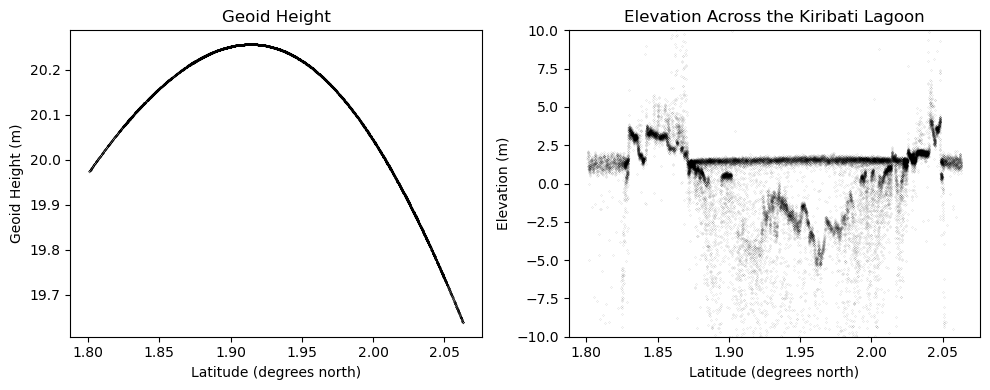

In [17]:
# make a figure
fig = plt.figure(figsize=(10,4))

# plot the longitude and latitude location in the first subplot
plt.subplot(1,2,1)
plt.plot(latitude,geoid_points,'k.',markersize=0.1)
plt.xlabel('Latitude (degrees north)')
plt.ylabel('Geoid Height (m)')
plt.title('Geoid Height')

# plot the elevation as a function of latitude in the second subplot
plt.subplot(1,2,2)
plt.plot(latitude,elevation-geoid_points,'k.',markersize=0.1)
plt.title('Elevation Across the Kiribati Lagoon')
plt.gca().set_ylim([-10, 10])
plt.ylabel('Elevation (m)')
plt.xlabel('Latitude (degrees north)')

plt.tight_layout()

# show the plot
plt.show()

#### &#129300; Consider these questions:
1. How does the removal of the geoid affect our interpretation of the elevation values?
2. With these changes, we might expect elevation to be 0 at sea level, but that's still not the case. What is going on here?
3. What else should be considered here when generating a bathymetry map from this calculation?

## Part 3: Writing Data to Shapefiles
In the plots above, we get a sense of where the ground track is by looking at the longitude and latitude values. However, we often want to visualize data on plots as well as maps in GIS. There are several packages in Python to convert geospatial datasets to shapefiles for viewing and editing in GIS. Here, we'll use the `shapefile` package to generate a shapefile of the ground track locations for use in QGIS.

### Slice the data
When reading in the files, the data are going to be very dense - there's almost 30,000 points. To make the datasets easier to work with and plot, it's helpful to subset the data using a defined skip interval:

In [18]:
# subset the data by slicing it
skip = 10
longitudes_subset = longitude[::skip]
latitudes_subset = latitude[::skip]
elevations_subset = elevation[::skip]
beams_subset = [beam]*len(elevations_subset)

### Write the shapefile
Once the data has been extracted from the file and isolated, it can be written out to a file:

In [19]:
# define an output file path
output_path = os.path.join(data_folder,file_name[:5]+'_points')

# open a shapefile Writer object for the given path
w = shapefile.Writer(output_path)

# create fields for the beam and elevation data
w.field('Beam','C')
w.field('Elevation','N')

# loop through each point
for i in range(len(longitudes_subset)):

    # add the point to the writer object
    w.point(longitudes_subset[i], latitudes_subset[i])

    # add a record for the data (the beam and elevation data)
    w.record(beams_subset[i], elevations_subset[i])

# close the file
w.close()

# write prj file
prj_text = ('GEOGCS["GCS_WGS_1984",'
                   'DATUM["D_WGS_1984",'
                         'SPHEROID["WGS_1984",6378137,298.257223563]],'
                   'PRIMEM["Greenwich",0],'
                   'UNIT["Degree",0.017453292519943295]]')
with open(output_path+'.prj','w') as f:
    f.write(prj_text)

Now, pop over to QGIS and import the data. Then, format the shapefile to show your ground track on your satellite image. When complete, output the image to a file called `Kiribati_ATL03.png` in your data folder. When complete, run the following code to generate a nice figure of your profile and the results:

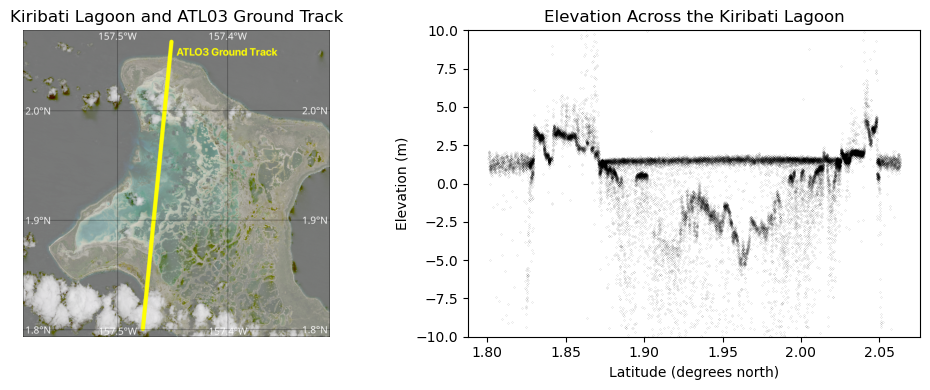

In [20]:
# make a figure
fig = plt.figure(figsize=(10,4))

# plot the longitude and latitude location in the first subplot
plt.subplot(1,2,1)
img = mpimg.imread(os.path.join(data_folder, 'Kiribati_ATL03.png'))
plt.imshow(img)
plt.axis('off')
plt.title('Kiribati Lagoon and ATL03 Ground Track')

# plot the elevation as a function of latitude in the second subplot
plt.subplot(1,2,2)
plt.plot(latitude,elevation-geoid_points,'k.',markersize=0.1)
plt.title('Elevation Across the Kiribati Lagoon')
plt.gca().set_ylim([-10, 10])
plt.ylabel('Elevation (m)')
plt.xlabel('Latitude (degrees north)')

plt.tight_layout()

# show the plot
plt.show()

## &#129300; Try it for yourself!

Using this same approach, examine another region in the ocean with shallow bathymetry. Keep in mind that the water needs to be relatively clear and shallow for this approach to work. A good test when considering your area of interest: if you can't see the ocean floor with your eyes, ICESat-2 probably can't see it either.